<a href="https://colab.research.google.com/github/mayurinarvekar01/ml35/blob/main/KMeans_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: K-Means Clustering

**Author: Dr. Priya B. Pandharbale**

**Aim:** To apply K-Means clustering and evaluate the clusters using the Elbow Method and Silhouette Score.

**Libraries:** NumPy, Matplotlib and Scikit-learn

Run the following cells one by one.

## 1. Import libraries and create data

In [13]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create simple sample data with 3 groups
X, y = make_blobs(n_samples=200, centers=3, random_state=50)

print("Dataset created successfully")
print("Number of samples:", len(X))

Dataset created successfully
Number of samples: 200


## 2. Display the dataset

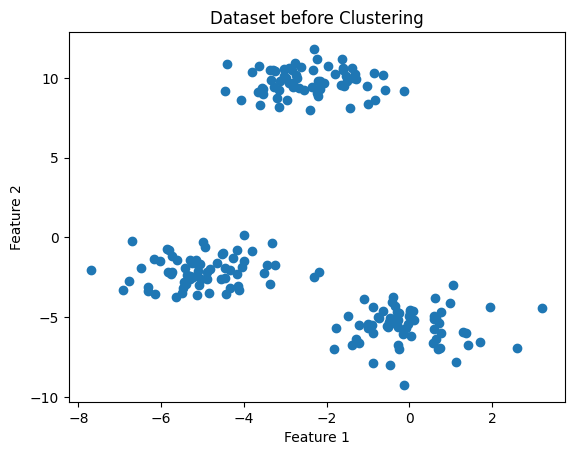

In [14]:
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset before Clustering")
plt.show()

## 3. Find the number of clusters using the Elbow Method

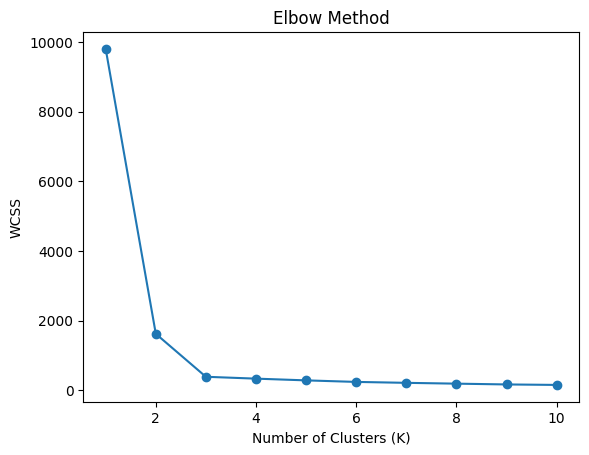

In [15]:
# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=50, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

# Plot the Elbow graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

**Observation:** WCSS decreases when the number of clusters increases. The suitable number of clusters is selected by looking for the point where the decrease starts becoming slower (the elbow). In this dataset, the elbow is expected around K = 3.

## 4. Apply K-Means with 3 clusters

In [16]:
# Create and train the K-Means model
model = KMeans(n_clusters=3, random_state=50, n_init=10)
labels = model.fit_predict(X)

# Display cluster centres
print("Cluster Centres:")
print(model.cluster_centers_)

Cluster Centres:
[[-4.98157791e+00 -2.08339452e+00]
 [-2.44043317e+00  9.77989806e+00]
 [-9.50351932e-03 -5.56209707e+00]]


## 5. Visualize the clusters

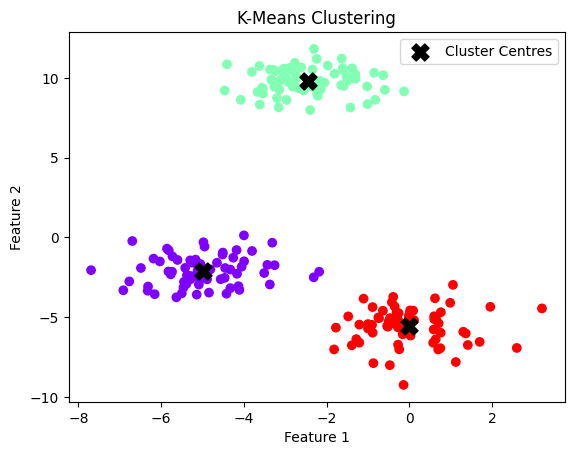

In [17]:
# Plot data points with their cluster labels
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow")

# Plot cluster centres
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color="black",
    marker="X",
    s=150,
    label="Cluster Centres"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

**Observation:** K-Means assigns each data point to the nearest cluster centre. Points with the same cluster label are shown in the same colour.

## 6. Evaluate using Silhouette Score

In [18]:
# Calculate Silhouette Score
score = silhouette_score(X, labels)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.76


**Observation:** The Silhouette Score ranges from -1 to +1. A score closer to +1 indicates that clusters are well separated. A score near 0 indicates overlapping clusters, while a negative score may indicate that some points are assigned to unsuitable clusters.

## Result

K-Means clustering was successfully applied to the sample dataset. The Elbow Method was used to identify a suitable number of clusters, the clusters were visualized, and the Silhouette Score was calculated to evaluate cluster quality.